In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import dendrogram, linkage

In [6]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

In [7]:
print("First Five Records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

First Five Records:
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'

In [8]:
df.columns = df.columns.str.strip().str.upper()

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Select important numerical sales features
# These columns are commonly available in this dataset.
preferred_features = [
    "QUANTITYORDERED",
    "PRICEEACH",
    "SALES",
    "MSRP"
]


In [9]:
features = [
    col for col in preferred_features if col in df.columns
]

# If preferred columns are unavailable,
# automatically select other suitable numerical columns.
if len(features) < 2:

    excluded_columns = [
        "ORDERNUMBER",
        "ORDERLINENUMBER",
        "CUSTOMERNUMBER",
        "YEAR_ID",
        "MONTH_ID",
        "QTR_ID",
        "POSTALCODE"
    ]

    features = [
        col for col in df.select_dtypes(include=np.number).columns
        if col not in excluded_columns
    ]

print("\nSelected Features:")
print(features)


Selected Features:
['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']


In [10]:
# Convert selected columns into numerical format
X = df[features].apply(pd.to_numeric, errors="coerce")

# Replace infinite values with missing values
X.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove columns containing only missing values
X.dropna(axis=1, how="all", inplace=True)

# Fill missing values with median
X = X.fillna(X.median())

# Remove constant columns because they do not help clustering
X = X.loc[:, X.nunique() > 1]

if X.shape[1] < 2:
    raise ValueError("At least two useful numerical features are required.")

# Keep only rows having valid feature data
df = df.loc[X.index].copy()

print("\nDataset After Preprocessing:")
print(X.head())

print("\nFinal Dataset Shape:", X.shape)




Dataset After Preprocessing:
   QUANTITYORDERED  PRICEEACH    SALES  MSRP
0               30      95.70  2871.00    95
1               34      81.35  2765.90    95
2               41      94.74  3884.34    95
3               45      83.26  3746.70    95
4               49     100.00  5205.27    95

Final Dataset Shape: (2823, 4)


In [11]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("\nStandardized Data:")
print(X_scaled[:5])



Standardized Data:
[[-0.52289086  0.5969775  -0.37082523 -0.14224584]
 [-0.11220131 -0.11445035 -0.42789707 -0.14224584]
 [ 0.60650538  0.54938372  0.17944282 -0.14224584]
 [ 1.01719493 -0.01975856  0.10470098 -0.14224584]
 [ 1.42788447  0.81015797  0.89673966 -0.14224584]]


In [12]:
# Maximum number of clusters to test
max_k = min(10, len(X) - 1)

k_values = range(1, max_k + 1)

wcss = []

# Calculate WCSS for different K values
for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    wcss.append(model.inertia_)

    print("K =", k, "| WCSS =", round(model.inertia_, 2))

C:\Users\RUPESH SHETE\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\RUPESH SHETE\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\RUPESH SHETE\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\RUPESH SHETE\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\RUPESH SHETE\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    h

K = 1 | WCSS = 11292.0
K = 2 | WCSS = 6741.69
K = 3 | WCSS = 4766.01
K = 4 | WCSS = 3934.89
K = 5 | WCSS = 3348.27
K = 6 | WCSS = 2858.82
K = 7 | WCSS = 2548.54
K = 8 | WCSS = 2350.66
K = 9 | WCSS = 2169.97
K = 10 | WCSS = 2019.75


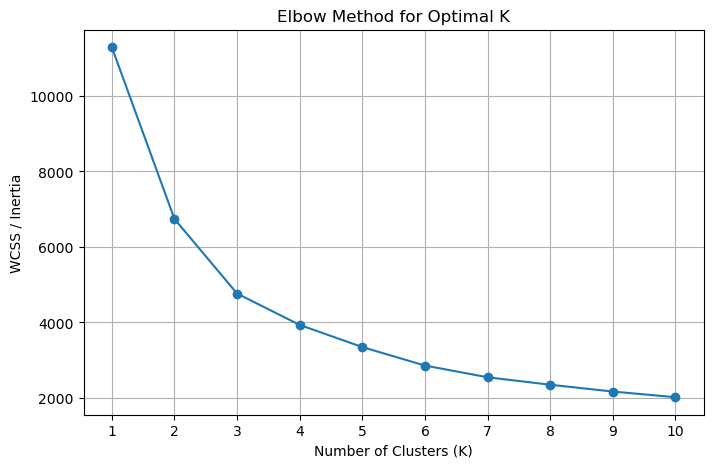

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    wcss,
    marker="o",
    linestyle="-"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")

plt.title("Elbow Method for Optimal K")

plt.xticks(list(k_values))
plt.grid(True)

plt.show()


In [16]:

if len(wcss) > 2:

    # Normalize K and WCSS values for comparison
    x_normalized = np.array(list(k_values), dtype=float)

    y_normalized = np.array(wcss, dtype=float)

    x_normalized = (
        (x_normalized - x_normalized.min()) /
        (x_normalized.max() - x_normalized.min())
    )

    if y_normalized.max() != y_normalized.min():

        y_normalized = (
            (y_normalized - y_normalized.min()) /
            (y_normalized.max() - y_normalized.min())
        )
           # Calculate distance from the straight line
    # connecting the first and last points
    points = np.column_stack((x_normalized, y_normalized))

    line = points[-1] - points[0]

    difference = points[1:-1] - points[0]

    distances = np.abs(
        line[0] * difference[:, 1] -
        line[1] * difference[:, 0]
    ) / np.linalg.norm(line)

    suggested_k = list(k_values)[
        1 + np.argmax(distances)
    ]

else:
    suggested_k = 2

print("\nSuggested Optimal Number of Clusters:", suggested_k)

# Allow user to confirm or change K
choice = input(
    "Enter number of clusters K (Press Enter to use suggested K): "
)

if choice.strip() == "":
    optimal_k = suggested_k

else:
    optimal_k = int(choice)

# Validate cluster count
if optimal_k < 2 or optimal_k >= len(X):
    raise ValueError("K must be between 2 and number of records - 1.")

print("\nFinal Number of Clusters:", optimal_k)



Suggested Optimal Number of Clusters: 3


Enter number of clusters K (Press Enter to use suggested K):  2



Final Number of Clusters: 2


In [17]:

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Train the K-Means model and assign cluster labels
kmeans_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to the original dataset
df["KMEANS_CLUSTER"] = kmeans_labels

print("\nK-Means Clustering Results:")
print(df[["KMEANS_CLUSTER"]].head(10))

print("\nNumber of Records in Each K-Means Cluster:")
print(df["KMEANS_CLUSTER"].value_counts().sort_index())



K-Means Clustering Results:
   KMEANS_CLUSTER
0               0
1               1
2               0
3               0
4               0
5               0
6               1
7               0
8               0
9               0

Number of Records in Each K-Means Cluster:
KMEANS_CLUSTER
0    1597
1    1226
Name: count, dtype: int64


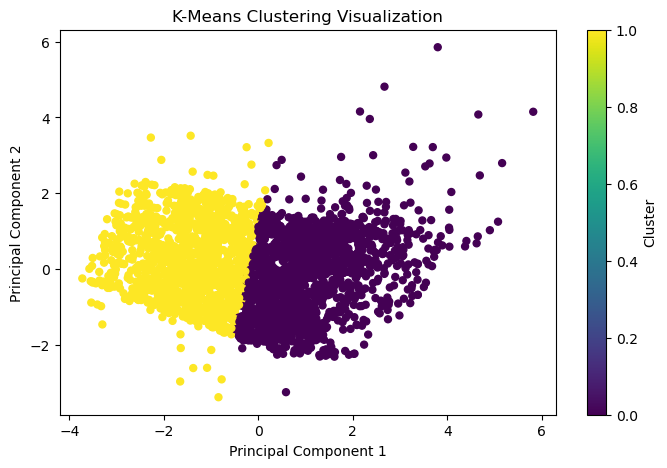

In [18]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=25
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("K-Means Clustering Visualization")

plt.colorbar(label="Cluster")

plt.show()

In [19]:
hierarchical = AgglomerativeClustering(
    n_clusters=optimal_k,
    linkage="ward"
)

# Perform hierarchical clustering
hierarchical_labels = hierarchical.fit_predict(X_scaled)

# Add cluster labels to the dataset
df["HIERARCHICAL_CLUSTER"] = hierarchical_labels

print("\nHierarchical Clustering Results:")
print(df[["HIERARCHICAL_CLUSTER"]].head(10))

print("\nNumber of Records in Each Hierarchical Cluster:")
print(
    df["HIERARCHICAL_CLUSTER"].value_counts().sort_index()
)


Hierarchical Clustering Results:
   HIERARCHICAL_CLUSTER
0                     0
1                     0
2                     1
3                     1
4                     0
5                     1
6                     0
7                     0
8                     0
9                     0

Number of Records in Each Hierarchical Cluster:
HIERARCHICAL_CLUSTER
0    1619
1    1204
Name: count, dtype: int64


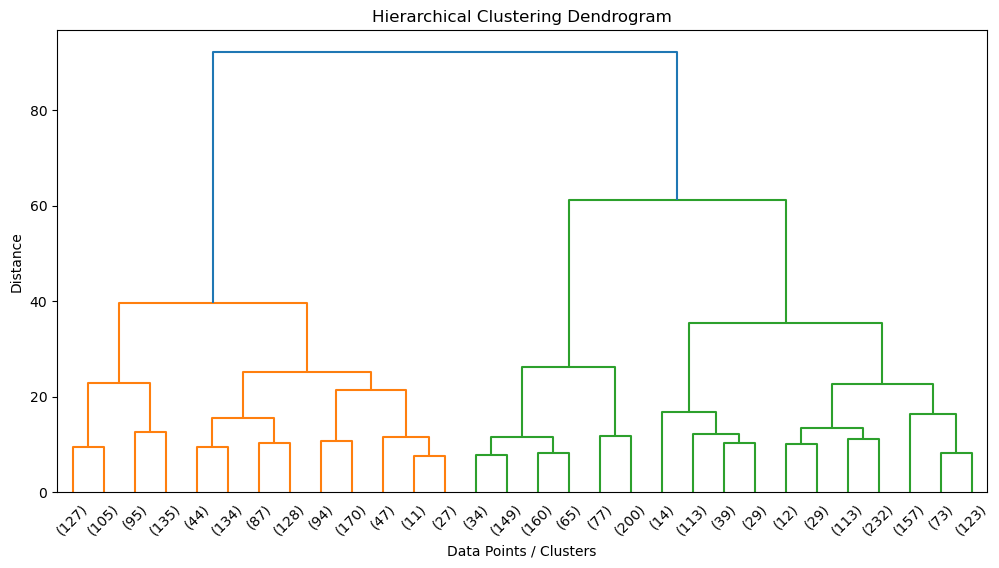

In [20]:
linkage_matrix = linkage(
    X_scaled,
    method="ward"
)

plt.figure(figsize=(12, 6))

dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)

plt.title("Hierarchical Clustering Dendrogram")

plt.xlabel("Data Points / Clusters")

plt.ylabel("Distance")

plt.show()


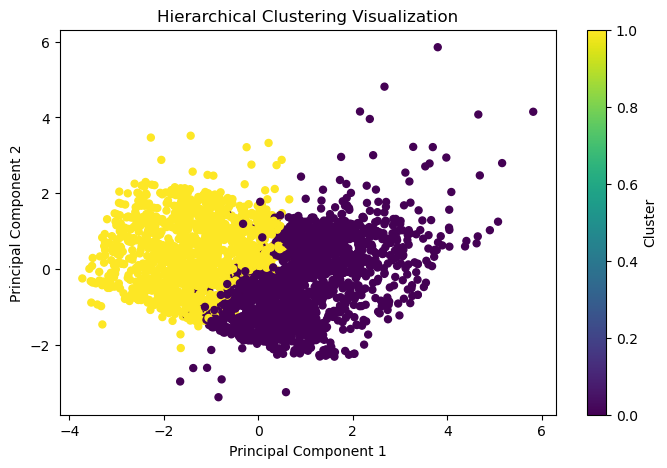

In [21]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=hierarchical_labels,
    cmap="viridis",
    s=25
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("Hierarchical Clustering Visualization")

plt.colorbar(label="Cluster")

plt.show()


In [22]:
sample_size = min(1000, len(X_scaled))

kmeans_score = silhouette_score(
    X_scaled,
    kmeans_labels,
    sample_size=sample_size,
    random_state=42
)

hierarchical_score = silhouette_score(
    X_scaled,
    hierarchical_labels,
    sample_size=sample_size,
    random_state=42
)

print("\nK-Means Silhouette Score:", round(kmeans_score, 4))

print(
    "Hierarchical Silhouette Score:",
    round(hierarchical_score, 4)
)


K-Means Silhouette Score: 0.3461
Hierarchical Silhouette Score: 0.3264


In [23]:
comparison = pd.DataFrame({

    "Clustering Algorithm": [
        "K-Means",
        "Hierarchical"
    ],

    "Number of Clusters": [
        optimal_k,
        optimal_k
    ],

    "Silhouette Score": [
        kmeans_score,
        hierarchical_score
    ]

})

print("\nCLUSTERING MODEL COMPARISON:")

print(comparison.to_string(index=False))

# Identify better clustering result based on Silhouette Score
if kmeans_score > hierarchical_score:

    print("\nBetter Clustering Method: K-Means")

elif hierarchical_score > kmeans_score:

    print("\nBetter Clustering Method: Hierarchical Clustering")

else:

    print("\nBoth methods have equal Silhouette Scores.")


# ==============================================================
# CELL 15: DISPLAY CLUSTER-WISE SALES SUMMARY
#
# Purpose:
# Calculate average sales, quantity and price
# for each K-Means cluster.
#
# This helps understand the characteristics
# of different sales groups.
#
# ==============================================================

print("\nK-MEANS CLUSTER SUMMARY:")

summary = (
    df.groupby("KMEANS_CLUSTER")[features]
    .mean()
    .round(2)
)

print(summary)

print("\nHIERARCHICAL CLUSTER SUMMARY:")

hierarchical_summary = (
    df.groupby("HIERARCHICAL_CLUSTER")[features]
    .mean()
    .round(2)
)

print(hierarchical_summary)


CLUSTERING MODEL COMPARISON:
Clustering Algorithm  Number of Clusters  Silhouette Score
             K-Means                   2          0.346136
        Hierarchical                   2          0.326397

Better Clustering Method: K-Means

K-MEANS CLUSTER SUMMARY:
                QUANTITYORDERED  PRICEEACH    SALES    MSRP
KMEANS_CLUSTER                                             
0                         36.33      98.05  4634.37  125.08
1                         33.48      64.91  2146.44   68.98

HIERARCHICAL CLUSTER SUMMARY:
                      QUANTITYORDERED  PRICEEACH    SALES    MSRP
HIERARCHICAL_CLUSTER                                             
0                               34.81      98.47  4506.44  123.15
1                               35.48      63.75  2273.01   70.55


In [ ]:
df.to_csv("sales_data_clustered.csv", index=False)

print("\nClustered dataset saved successfully!")

print("Output File: sales_data_clustered.csv")